BASE PENSE 2024 - QUI-QUADRADO E V DE CRAMÉR
Número de estudantes/linhas: 118,036
Número total de variáveis: 39
Variáveis categóricas elegíveis: 39
Pares de variáveis a analisar: 741
Pares processados: 500/741
Pares processados: 741/741


## Resumo da análise

Estudantes/linhas na base: 118,036
Variáveis analisadas: 39
Pares válidos calculados: 741
Pares com p-valor ajustado (BH) < 0.05: 712


## Top 20 associações por V de Cramér corrigido

,Variavel_1,Variavel_2,N,Qui_quadrado,Graus_liberdade,P_valor,P_valor_BH,V_Cramer_corrigido,Frequencia_esperada_minima,Percentual_esperadas_menor_5
0,E01P11801 - Quais tipos de suporte a escola oferece? - A escola possui em seu quadro de funcionários profissional de saúde psicológica/mental,E01P11802 - Quais tipos de suporte a escola oferece? - A escola conta com serviço terceirizado de profissional de saúde psicológica/mental,118036,123324.073,4,0.000e+00,0.000e+00,0.7228,3273.46,0.0%
1,"E01P8505 - NOS ÚLTIMOS 12 MESES, a escola desenvolveu quais dessas seguintes ações? - Prevenção de violências e acidentes","E01P8510 - NOS ÚLTIMOS 12 MESES, a escola desenvolveu quais dessas seguintes ações? - Prevenção de práticas de bullying nas dependências da escola",118036,119818.943,4,0.000e+00,0.000e+00,0.7124,2.33,11.1%
2,"E01P117 - NOS ÚLTIMOS 12 MESES, a escola contou com algum suporte psicológico para situações de bullying e violências ocorridas na escola para alunos, professores e funcionários?",E01P11801 - Quais tipos de suporte a escola oferece? - A escola possui em seu quadro de funcionários profissional de saúde psicológica/mental,118036,119619.421,8,0.000e+00,0.000e+00,0.7118,26.59,0.0%
3,"E01P117 - NOS ÚLTIMOS 12 MESES, a escola contou com algum suporte psicológico para situações de bullying e violências ocorridas na escola para alunos, professores e funcionários?",E01P11802 - Quais tipos de suporte a escola oferece? - A escola conta com serviço terceirizado de profissional de saúde psicológica/mental,118036,115170.630,8,0.000e+00,0.000e+00,0.6985,21.33,0.0%
4,"B09016A1 - Alguma vez na vida alguém o(a) tocou, manipulou, beijou ou expôs partes do corpo contra a sua vontade?","B09016A2 - Alguma vez na vida alguém ameaçou, intimidou ou obrigou a ter relações sexuais ou qualquer outro ato sexual contra a sua vontade?",118036,102962.924,4,0.000e+00,0.000e+00,0.6604,15.65,0.0%
5,"B09001 - NOS ÚLTIMOS 30 DIAS, em quantos dias você deixou de ir à escola porque não se sentia seguro NO CAMINHO de casa para a escola ou da escola para casa?","B09002 - NOS ÚLTIMOS 30 DIAS, em quantos dias você não foi à escola porque não se sentia seguro NA ESCOLA?",118036,100774.979,4,0.000e+00,0.000e+00,0.6534,12.32,0.0%
6,"B09003A - NOS ÚLTIMOS 12 MESES, quantas vezes você foi agredido(a) fisicamente por sua mãe, pai ou responsável?","B09010A1 - NOS ÚLTIMOS 12 MESES, quantas vezes você foi agredido(a) fisicamente por OUTRA PESSOA que não seja sua mãe, pai ou responsável?",118036,92457.510,4,0.000e+00,0.000e+00,0.6258,14.33,0.0%
7,"B12008 - NOS ÚLTIMOS 30 DIAS, com que frequência você sentiu que a vida não vale a pena ser vivida?","B12009 - NOS ÚLTIMOS 12 MESES, alguma vez você sentiu vontade de se machucar de propósito?",118036,80219.443,6,0.000e+00,0.000e+00,0.5829,4.35,8.3%
8,"B09010A1 - NOS ÚLTIMOS 12 MESES, quantas vezes você foi agredido(a) fisicamente por OUTRA PESSOA que não seja sua mãe, pai ou responsável?","B09016A1 - Alguma vez na vida alguém o(a) tocou, manipulou, beijou ou expôs partes do corpo contra a sua vontade?",118036,75545.624,4,0.000e+00,0.000e+00,0.5657,14.87,0.0%
9,"B12005 - NOS ÚLTIMOS 30 DIAS, com que frequência você se sentiu triste?","B12009 - NOS ÚLTIMOS 12 MESES, alguma vez você sentiu vontade de se machucar de propósito?",118036,73613.835,6,0.000e+00,0.000e+00,0.5584,3.52,8.3%


/var/folders/6q/rl1jn5t52qg9qxc6f3l113480000gn/T/ipykernel_3136/2470020169.py:335: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


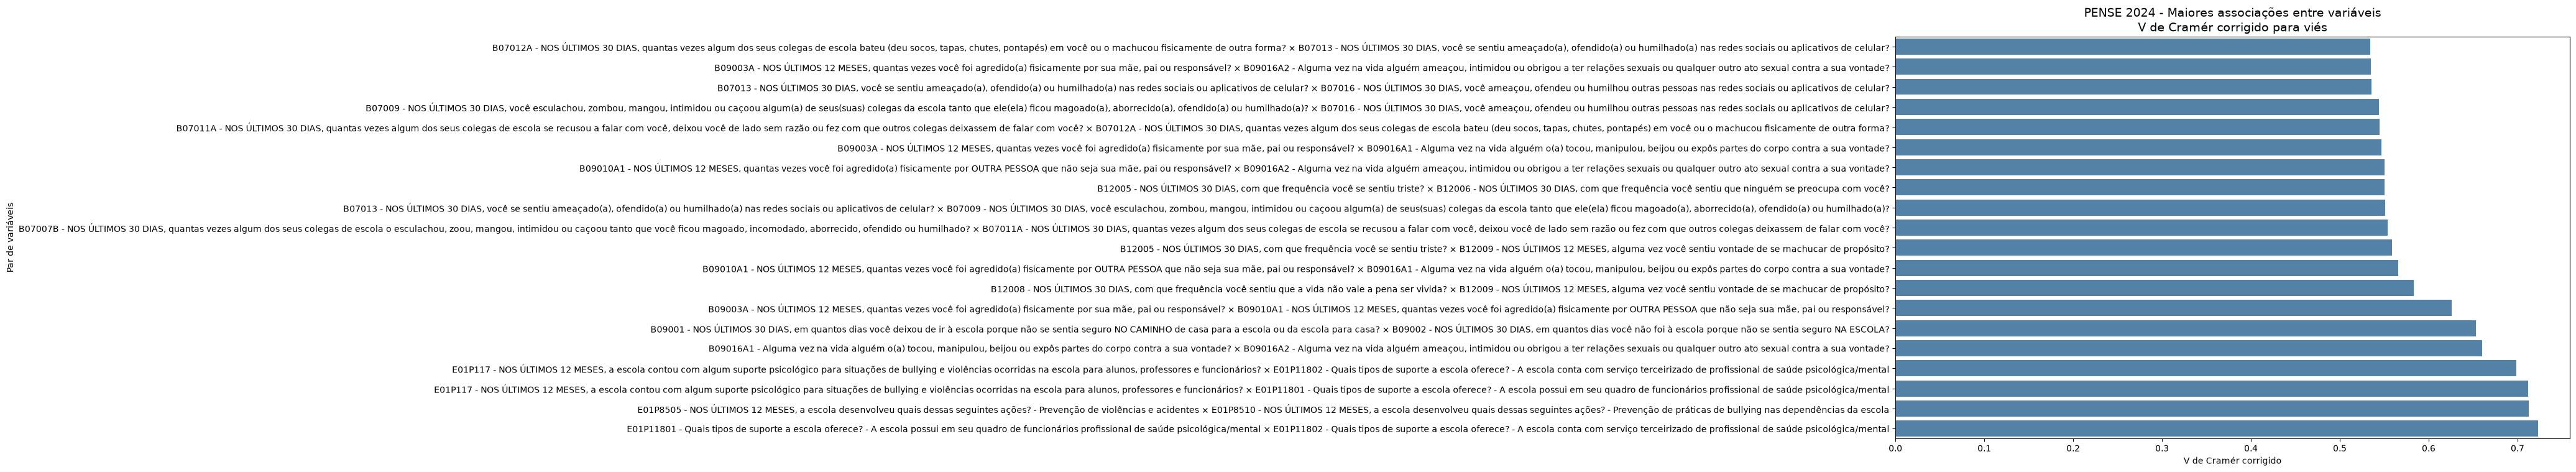

## Análise concluída

Resultados mantidos na memória do notebook:
- df_resultados: tabela completa de todos os pares válidos
- top: pares usados no gráfico
- df: base de entrada

Nenhum arquivo externo de resultados foi gravado.


In [1]:

# ============================================================
# QUI-QUADRADO DE INDEPENDÊNCIA + V DE CRAMÉR CORRIGIDO
# PENSE 2024 - Estudantes de 13 a 17 anos
# Resultados exibidos no próprio Jupyter Notebook
# Nenhum arquivo externo será gravado
# ============================================================

import warnings
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency
from IPython.display import display, Markdown

# ============================================================
# 1. CONFIGURAÇÕES
# ============================================================

caminho_base = (
    "/Users/claudiojacomassi/Documents/GitHub/"
    "Suicidio_adolescentes_Brasil/"
    "02_Tratamento_dados_database_PENSE_2024/"
    "02_Scripts_tratamento_dados_PENSE_2024/"
    "07_PENSE2024_IDADE_13_A_17_CATEGORY.feather"
)

# Número de associações mostradas na tabela final
NUM_ASSOCIACOES_EXIBIDAS = 20

# Opcional: limitar o número de variáveis para teste inicial.
# None = analisar todas as variáveis categóricas elegíveis.
MAX_VARIAVEIS = None

# Excluir variáveis que não devem participar da análise.
# Preencha com os nomes exatos das colunas, se necessário.
EXCLUIR_COLUNAS = []

# Nível de significância
ALFA = 0.05

# ============================================================
# 2. CARREGAR A BASE DE DADOS
# ============================================================

df = pd.read_feather(caminho_base)

print("=" * 75)
print("BASE PENSE 2024 - QUI-QUADRADO E V DE CRAMÉR")
print("=" * 75)

print(f"Número de estudantes/linhas: {df.shape[0]:,}")
print(f"Número total de variáveis: {df.shape[1]:,}")

# ============================================================
# 3. SELECIONAR VARIÁVEIS CATEGÓRICAS
# ============================================================

# A base foi identificada como CATEGORY, mas verificamos os tipos
# efetivamente armazenados no Feather.
colunas_categoricas = [
    col for col in df.columns
    if (
        isinstance(df[col].dtype, pd.CategoricalDtype)
        or pd.api.types.is_object_dtype(df[col].dtype)
        or pd.api.types.is_string_dtype(df[col].dtype)
        or pd.api.types.is_bool_dtype(df[col].dtype)
    )
]

# Excluir colunas indicadas pelo usuário
colunas_categoricas = [
    col for col in colunas_categoricas
    if col not in EXCLUIR_COLUNAS
]

# Retirar variáveis constantes ou sem informação suficiente
colunas_validas = []

for col in colunas_categoricas:
    valores_validos = df[col].dropna()

    if len(valores_validos) > 0 and valores_validos.nunique() >= 2:
        colunas_validas.append(col)

colunas_categoricas = colunas_validas

if MAX_VARIAVEIS is not None:
    colunas_categoricas = colunas_categoricas[:MAX_VARIAVEIS]

n_variaveis = len(colunas_categoricas)
total_pares = n_variaveis * (n_variaveis - 1) // 2

print(f"Variáveis categóricas elegíveis: {n_variaveis:,}")
print(f"Pares de variáveis a analisar: {total_pares:,}")

if n_variaveis < 2:
    raise ValueError(
        "São necessárias pelo menos duas variáveis categóricas "
        "com duas ou mais categorias observadas."
    )

# ============================================================
# 4. FUNÇÃO: V DE CRAMÉR CORRIGIDO PARA VIÉS
# ============================================================

def calcular_v_cramer_corrigido(chi2, n, linhas, colunas):
    """
    Calcula o V de Cramér corrigido para viés.
    Retorna NaN quando o resultado não é definido.
    """

    if n <= 1 or linhas < 2 or colunas < 2:
        return np.nan

    phi2 = chi2 / n

    phi2_corr = max(
        0,
        phi2 - ((colunas - 1) * (linhas - 1)) / (n - 1)
    )

    linhas_corr = linhas - ((linhas - 1) ** 2) / (n - 1)
    colunas_corr = colunas - ((colunas - 1) ** 2) / (n - 1)

    denominador = min(linhas_corr - 1, colunas_corr - 1)

    if denominador <= 0:
        return np.nan

    return np.sqrt(phi2_corr / denominador)


# ============================================================
# 5. CALCULAR QUI-QUADRADO E V DE CRAMÉR PARA TODOS OS PARES
# ============================================================

resultados = []

for numero, (var1, var2) in enumerate(
    combinations(colunas_categoricas, 2),
    start=1
):

    # Excluir valores ausentes apenas para este par
    dados_par = df[[var1, var2]].dropna()

    n = len(dados_par)

    # Tabela de contingência
    tabela = pd.crosstab(
        dados_par[var1],
        dados_par[var2]
    )

    # Exigir pelo menos duas categorias observadas em cada variável
    if tabela.shape[0] < 2 or tabela.shape[1] < 2:
        continue

    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")

            chi2, p_valor, gl, esperadas = chi2_contingency(
                tabela,
                correction=False
            )

        v_cramer = calcular_v_cramer_corrigido(
            chi2=chi2,
            n=n,
            linhas=tabela.shape[0],
            colunas=tabela.shape[1]
        )

        resultados.append({
            "Variavel_1": var1,
            "Variavel_2": var2,
            "N": n,
            "Categorias_1": tabela.shape[0],
            "Categorias_2": tabela.shape[1],
            "Qui_quadrado": chi2,
            "Graus_liberdade": gl,
            "P_valor": p_valor,
            "V_Cramer_corrigido": v_cramer,
            "Frequencia_esperada_minima": esperadas.min(),
            "Percentual_esperadas_menor_5": (
                (esperadas < 5).mean() * 100
            )
        })

    except (ValueError, ZeroDivisionError):
        continue

    if numero % 500 == 0 or numero == total_pares:
        print(f"Pares processados: {numero:,}/{total_pares:,}")

# ============================================================
# 6. MONTAR A TABELA FINAL
# ============================================================

df_resultados = pd.DataFrame(resultados)

if df_resultados.empty:
    raise ValueError(
        "Nenhum par válido foi encontrado. Verifique os dados."
    )

# Correção de Benjamini-Hochberg para testes múltiplos
# Implementação sem dependência adicional.
p = df_resultados["P_valor"].to_numpy()
m = len(p)

ordem = np.argsort(p)
p_ordenados = p[ordem]

p_ajustados_ordenados = p_ordenados * m / np.arange(1, m + 1)
p_ajustados_ordenados = np.minimum.accumulate(
    p_ajustados_ordenados[::-1]
)[::-1]

p_ajustados_ordenados = np.clip(
    p_ajustados_ordenados, 0, 1
)

p_ajustados = np.empty(m)
p_ajustados[ordem] = p_ajustados_ordenados

df_resultados["P_valor_BH"] = p_ajustados

df_resultados["Significativo_05_BH"] = (
    df_resultados["P_valor_BH"] < ALFA
)

df_resultados = df_resultados.sort_values(
    "V_Cramer_corrigido",
    ascending=False
).reset_index(drop=True)

# ============================================================
# 7. EXIBIR RESUMO GERAL
# ============================================================

display(Markdown("## Resumo da análise"))

print(f"Estudantes/linhas na base: {len(df):,}")
print(f"Variáveis analisadas: {n_variaveis:,}")
print(f"Pares válidos calculados: {len(df_resultados):,}")
print(
    "Pares com p-valor ajustado (BH) < "
    f"{ALFA}: "
    f"{df_resultados['Significativo_05_BH'].sum():,}"
)

# ============================================================
# 8. EXIBIR RANKING DAS MAIORES ASSOCIAÇÕES
# ============================================================

display(Markdown(
    f"## Top {NUM_ASSOCIACOES_EXIBIDAS} associações "
    "por V de Cramér corrigido"
))

colunas_exibicao = [
    "Variavel_1",
    "Variavel_2",
    "N",
    "Qui_quadrado",
    "Graus_liberdade",
    "P_valor",
    "P_valor_BH",
    "V_Cramer_corrigido",
    "Frequencia_esperada_minima",
    "Percentual_esperadas_menor_5"
]

display(
    df_resultados[colunas_exibicao]
    .head(NUM_ASSOCIACOES_EXIBIDAS)
    .style.format({
        "Qui_quadrado": "{:.3f}",
        "P_valor": "{:.3e}",
        "P_valor_BH": "{:.3e}",
        "V_Cramer_corrigido": "{:.4f}",
        "Frequencia_esperada_minima": "{:.2f}",
        "Percentual_esperadas_menor_5": "{:.1f}%"
    })
)

# ============================================================
# 9. GRÁFICO DAS MAIORES ASSOCIAÇÕES
# ============================================================

top = (
    df_resultados
    .dropna(subset=["V_Cramer_corrigido"])
    .head(NUM_ASSOCIACOES_EXIBIDAS)
    .copy()
)

if not top.empty:

    top["Par"] = (
        top["Variavel_1"].astype(str)
        + " × "
        + top["Variavel_2"].astype(str)
    )

    top = top.sort_values("V_Cramer_corrigido")

    altura = max(6, len(top) * 0.42)

    fig, ax = plt.subplots(figsize=(14, altura))

    sns.barplot(
        data=top,
        x="V_Cramer_corrigido",
        y="Par",
        color="steelblue",
        ax=ax
    )

    ax.set_title(
        "PENSE 2024 - Maiores associações entre variáveis\n"
        "V de Cramér corrigido para viés",
        fontsize=14
    )

    ax.set_xlabel("V de Cramér corrigido")
    ax.set_ylabel("Par de variáveis")

    plt.tight_layout()
    plt.show()
    plt.close(fig)

# ============================================================
# 10. RESULTADOS DISPONÍVEIS NA MEMÓRIA
# ============================================================

display(Markdown("## Análise concluída"))

print("Resultados mantidos na memória do notebook:")
print("- df_resultados: tabela completa de todos os pares válidos")
print("- top: pares usados no gráfico")
print("- df: base de entrada")

print("\nNenhum arquivo externo de resultados foi gravado.")


In [3]:
# ============================================================
# PENSE 2024 — QUI-QUADRADO DE CADA VARIÁVEL VS B12009
# ============================================================

import numpy as np
import pandas as pd
import warnings

from scipy.stats import chi2_contingency
from statsmodels.stats.multitest import multipletests
from IPython.display import display, Markdown

# 1. CONFIGURAÇÕES
caminho_base = (
    "/Users/claudiojacomassi/Documents/GitHub/"
    "Suicidio_adolescentes_Brasil/"
    "02_Tratamento_dados_database_PENSE_2024/"
    "02_Scripts_tratamento_dados_PENSE_2024/"
    "07_PENSE2024_IDADE_13_A_17_CATEGORY.feather"
)

PREFIXO_ALVO = "B12009"
ALFA = 0.05

# 2. CARREGAR A BASE
df = pd.read_feather(caminho_base)

# Identificar a coluna-alvo
colunas_alvo = [
    c for c in df.columns
    if str(c).startswith(PREFIXO_ALVO)
]

if len(colunas_alvo) != 1:
    raise ValueError(
        f"Esperava encontrar uma coluna iniciada por "
        f"{PREFIXO_ALVO}; encontrei {len(colunas_alvo)}."
    )

coluna_alvo = colunas_alvo[0]

# 3. IDENTIFICAR VARIÁVEIS CATEGÓRICAS
def eh_categorica(serie):
    return (
        isinstance(serie.dtype, pd.CategoricalDtype)
        or pd.api.types.is_object_dtype(serie.dtype)
        or pd.api.types.is_string_dtype(serie.dtype)
        or pd.api.types.is_bool_dtype(serie.dtype)
    )

variaveis = [
    c for c in df.columns
    if c != coluna_alvo and eh_categorica(df[c])
]

# 4. V DE CRAMÉR CORRIGIDO PARA VIÉS
def calcular_v_cramer_corrigido(chi2, n, r, k):
    if n <= 1 or r < 2 or k < 2:
        return np.nan

    phi2 = chi2 / n

    phi2_corr = max(
        0,
        phi2 - ((k - 1) * (r - 1)) / (n - 1)
    )

    r_corr = r - ((r - 1) ** 2) / (n - 1)
    k_corr = k - ((k - 1) ** 2) / (n - 1)

    denominador = min(r_corr - 1, k_corr - 1)

    if denominador <= 0:
        return np.nan

    return np.sqrt(phi2_corr / denominador)

# 5. TESTAR CADA VARIÁVEL CONTRA B12009
resultados = []
ignoradas = []

for variavel_x in variaveis:

    dados = df[[variavel_x, coluna_alvo]].dropna()

    n = len(dados)

    tabela = pd.crosstab(
        dados[variavel_x],
        dados[coluna_alvo]
    )

    # É necessário haver pelo menos duas categorias em cada variável
    if tabela.shape[0] < 2 or tabela.shape[1] < 2:
        ignoradas.append(variavel_x)
        continue

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")

        chi2, p, gl, esperadas = chi2_contingency(
            tabela,
            correction=False
        )

    v_corrigido = calcular_v_cramer_corrigido(
        chi2=chi2,
        n=n,
        r=tabela.shape[0],
        k=tabela.shape[1]
    )

    resultados.append({
        "Variavel": variavel_x,
        "N": n,
        "Categorias_variavel": tabela.shape[0],
        "Categorias_B12009": tabela.shape[1],
        "Qui_quadrado": chi2,
        "Graus_liberdade": gl,
        "P_valor": p,
        "V_Cramer_corrigido": v_corrigido,
        "Frequencia_esperada_minima": esperadas.min(),
        "Percentual_esperadas_menor_5":
            (esperadas < 5).mean() * 100
    })

# 6. MONTAR RESULTADOS
df_resultados_B12009 = pd.DataFrame(resultados)

if df_resultados_B12009.empty:
    raise ValueError("Nenhum teste válido foi calculado.")

# Ajustar p-valores para múltiplos testes (Benjamini–Hochberg)
df_resultados_B12009["P_valor_BH"] = multipletests(
    df_resultados_B12009["P_valor"],
    alpha=ALFA,
    method="fdr_bh"
)[1]

df_resultados_B12009["Significativo_BH_05"] = (
    df_resultados_B12009["P_valor_BH"] < ALFA
)

# Ordenar pela força da associação
df_resultados_B12009 = (
    df_resultados_B12009
    .sort_values("V_Cramer_corrigido", ascending=False)
    .reset_index(drop=True)
)

# 7. EXIBIR TABELA COMPLETA
display(Markdown(
    "## Associação de cada variável categórica com B12009"
))

colunas_exibicao = [
    "Variavel",
    "N",
    "Qui_quadrado",
    "Graus_liberdade",
    "P_valor",
    "P_valor_BH",
    "V_Cramer_corrigido",
    "Frequencia_esperada_minima",
    "Percentual_esperadas_menor_5",
    "Significativo_BH_05"
]

display(
    df_resultados_B12009[colunas_exibicao].style.format({
        "Qui_quadrado": "{:.3f}",
        "P_valor": "{:.3e}",
        "P_valor_BH": "{:.3e}",
        "V_Cramer_corrigido": "{:.4f}",
        "Frequencia_esperada_minima": "{:.2f}",
        "Percentual_esperadas_menor_5": "{:.1f}%"
    })
)

print(f"Variável-alvo: {coluna_alvo}")
print(f"Testes válidos: {len(df_resultados_B12009)}")
print(
    "Associações significativas após ajuste BH: "
    f"{df_resultados_B12009['Significativo_BH_05'].sum()}"
)
print(f"Variáveis ignoradas por falta de categorias: {len(ignoradas)}")

## Associação de cada variável categórica com B12009

,Variavel,N,Qui_quadrado,Graus_liberdade,P_valor,P_valor_BH,V_Cramer_corrigido,Frequencia_esperada_minima,Percentual_esperadas_menor_5,Significativo_BH_05
0,"B12008 - NOS ÚLTIMOS 30 DIAS, com que frequência você sentiu que a vida não vale a pena ser vivida?",118036,80219.443,6,0.000e+00,0.000e+00,0.5829,4.35,8.3%,True
1,"B12005 - NOS ÚLTIMOS 30 DIAS, com que frequência você se sentiu triste?",118036,73613.835,6,0.000e+00,0.000e+00,0.5584,3.52,8.3%,True
2,"B12006 - NOS ÚLTIMOS 30 DIAS, com que frequência você sentiu que ninguém se preocupa com você?",118036,64721.355,6,0.000e+00,0.000e+00,0.5236,3.93,8.3%,True
3,"B12007 - NOS ÚLTIMOS 30 DIAS, com que frequência você se sentiu irritado(a), nervoso(a) ou mal-humorado(a) por qualquer coisa?",118036,61916.394,6,0.000e+00,0.000e+00,0.5121,3.89,8.3%,True
4,B12003 - Quantos(as) amigos(as) próximos você tem?,118036,45795.625,4,0.000e+00,0.000e+00,0.4404,2.91,11.1%,True
5,"B12004 - NOS ÚLTIMOS 30 DIAS, com que frequência você se sentiu muito preocupado com as coisas comuns do seu dia a dia como atividades da escola, competições esportivas, tarefas de casa, etc.?",118036,45251.517,6,0.000e+00,0.000e+00,0.4378,3.95,8.3%,True
6,"B07013 - NOS ÚLTIMOS 30 DIAS, você se sentiu ameaçado(a), ofendido(a) ou humilhado(a) nas redes sociais ou aplicativos de celular?",118036,43421.693,4,0.000e+00,0.000e+00,0.4289,3.00,11.1%,True
7,"B07016 - NOS ÚLTIMOS 30 DIAS, você ameaçou, ofendeu ou humilhou outras pessoas nas redes sociais ou aplicativos de celular?",118036,40849.971,4,0.000e+00,0.000e+00,0.4160,3.40,11.1%,True
8,"B07009 - NOS ÚLTIMOS 30 DIAS, você esculachou, zombou, mangou, intimidou ou caçoou algum(a) de seus(suas) colegas da escola tanto que ele(ela) ficou magoado(a), aborrecido(a), ofendido(a) ou humilhado(a)?",118036,37414.736,4,0.000e+00,0.000e+00,0.3981,3.48,11.1%,True
9,"B09016A1 - Alguma vez na vida alguém o(a) tocou, manipulou, beijou ou expôs partes do corpo contra a sua vontade?",118036,35915.665,4,0.000e+00,0.000e+00,0.3900,7.78,0.0%,True


Variável-alvo: B12009 - NOS ÚLTIMOS 12 MESES, alguma vez você sentiu vontade de se machucar de propósito?
Testes válidos: 38
Associações significativas após ajuste BH: 37
Variáveis ignoradas por falta de categorias: 0


In [5]:
from IPython.display import display

pares_nao_significativos_BH = (
    df_resultados[df_resultados["P_valor_BH"] >= 0.05]
    .sort_values("P_valor_BH", ascending=False)
)

colunas = [
    "Variavel_1",
    "Variavel_2",
    "P_valor",
    "P_valor_BH",
    "V_Cramer_corrigido",
    "N"
]

tabela_nao_significativos_BH = (
    pares_nao_significativos_BH[colunas]
    .style
    .set_properties(
        subset=["Variavel_1", "Variavel_2"],
        **{
            "white-space": "normal",
            "overflow-wrap": "anywhere",
            "min-width": "300px",
            "max-width": "450px",
            "text-align": "left",
            "vertical-align": "top"
        }
    )
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("white-space", "normal"),
                ("text-align", "left"),
                ("vertical-align", "top")
            ]
        }
    ])
    .format({
        "P_valor": "{:.6g}",
        "P_valor_BH": "{:.6g}",
        "V_Cramer_corrigido": "{:.4f}"
    })
)

display(tabela_nao_significativos_BH)

print(
    "Total de pares não significativos após BH:",
    len(pares_nao_significativos_BH)
)

pares_nao_significativos_BH.to_csv(
    "pares_qui_quadrado_nao_significativos_BH.csv",
    index=False,
    encoding="utf-8-sig"
)

,Variavel_1,Variavel_2,P_valor,P_valor_BH,V_Cramer_corrigido,N
736,"B07009 - NOS ÚLTIMOS 30 DIAS, você esculachou, zombou, mangou, intimidou ou caçoou algum(a) de seus(suas) colegas da escola tanto que ele(ela) ficou magoado(a), aborrecido(a), ofendido(a) ou humilhado(a)?","E01P8510 - NOS ÚLTIMOS 12 MESES, a escola desenvolveu quais dessas seguintes ações? - Prevenção de práticas de bullying nas dependências da escola",0.973051,0.973051,0.0000,118036
733,"B07012A - NOS ÚLTIMOS 30 DIAS, quantas vezes algum dos seus colegas de escola bateu (deu socos, tapas, chutes, pontapés) em você ou o machucou fisicamente de outra forma?","E01P8510 - NOS ÚLTIMOS 12 MESES, a escola desenvolveu quais dessas seguintes ações? - Prevenção de práticas de bullying nas dependências da escola",0.906797,0.908022,0.0000,118036
735,B01001A - Qual é o seu sexo?,E01P11802 - Quais tipos de suporte a escola oferece? - A escola conta com serviço terceirizado de profissional de saúde psicológica/mental,0.697112,0.698999,0.0000,118036
740,"B09016A1 - Alguma vez na vida alguém o(a) tocou, manipulou, beijou ou expôs partes do corpo contra a sua vontade?","E01P8510 - NOS ÚLTIMOS 12 MESES, a escola desenvolveu quais dessas seguintes ações? - Prevenção de práticas de bullying nas dependências da escola",0.676204,0.678952,0.0000,118036
738,"B09003A - NOS ÚLTIMOS 12 MESES, quantas vezes você foi agredido(a) fisicamente por sua mãe, pai ou responsável?","E01P8510 - NOS ÚLTIMOS 12 MESES, a escola desenvolveu quais dessas seguintes ações? - Prevenção de práticas de bullying nas dependências da escola",0.636592,0.640047,0.0000,118036
739,"B07005 - NOS ÚLTIMOS 30 DIAS, com que frequência seus pais ou responsáveis mexeram em suas coisas sem a sua concordância?","E01P8510 - NOS ÚLTIMOS 12 MESES, a escola desenvolveu quais dessas seguintes ações? - Prevenção de práticas de bullying nas dependências da escola",0.632183,0.636478,0.0000,118036
737,"B07005 - NOS ÚLTIMOS 30 DIAS, com que frequência seus pais ou responsáveis mexeram em suas coisas sem a sua concordância?","E01P8505 - NOS ÚLTIMOS 12 MESES, a escola desenvolveu quais dessas seguintes ações? - Prevenção de violências e acidentes",0.515303,0.519509,0.0000,118036
734,B01001A - Qual é o seu sexo?,"IDADE_AGREG - IDADE DO ESTUDANTE, CATEGORIAS",0.473194,0.477706,0.0000,118036
732,"B12009 - NOS ÚLTIMOS 12 MESES, alguma vez você sentiu vontade de se machucar de propósito?","E01P8510 - NOS ÚLTIMOS 12 MESES, a escola desenvolveu quais dessas seguintes ações? - Prevenção de práticas de bullying nas dependências da escola",0.409817,0.41429,0.0000,118036
731,"B09010A1 - NOS ÚLTIMOS 12 MESES, quantas vezes você foi agredido(a) fisicamente por OUTRA PESSOA que não seja sua mãe, pai ou responsável?","E01P8510 - NOS ÚLTIMOS 12 MESES, a escola desenvolveu quais dessas seguintes ações? - Prevenção de práticas de bullying nas dependências da escola",0.373713,0.378308,0.0010,118036


Total de pares não significativos após BH: 29
